# World Stress Map 2025 — Exploratory Data Analysis

**Analysis:** Python-based exploration of the World Stress Map (WSM) 2025 database  
**Data source:** [World Stress Map project](https://www.world-stress-map.org/)  

## Objective
Explore the structure, completeness, quality categories, and tectonic stress regimes of the WSM 2025 database. Examine which records are missing coordinates and create exploratory visualizations. Source records are inspected without overwriting the CSV.

**Input data:** `WSM_Database_2025.csv`, accessed through a relative project path.

## 1. Import libraries and load the dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("WSM_Database_2025.csv")
df = pd.read_csv(DATA_PATH, low_memory=False)

df.head()

,ID,ISC_ID,SITE,LAT,LON,AZI,TYPE,DEPTH,QUALITY,REGIME,LOCALITY,COUNTRY,DATE,TIME,NUMBER,SD,TOT_LEN,VENT,TOP,BOT,ANISOTROPY,METHOD,S1AZ,S1PL,S2AZ,S2PL,S3AZ,S3PL,MAG_TYPE,EQ_MAG,CRUST,REF1,REF2,REF3,REF4,REF5,REF6,COMMENT,PLATE,DIST
0,wsm00015,NaN,TU42,36.880,30.670,0,OC,0.31,C,U,Oymapinar-An,Turkey,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN,NaN,FJ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,CAKIXX1971,NaN,NaN,NaN,NaN,NaN,FRSDB,AT,170.0
1,wsm00016,NaN,TU41,40.180,29.100,0,OC,0.17,B,NF,Uludag-Bursa,Turkey,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN,NaN,FJ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,KOSEXX1983,NaN,NaN,NaN,NaN,NaN,FRSDB,AT,57.0
2,wsm00017,NaN,TU40,41.800,33.690,0,OC,0.16,C,NF,Kure-Asikoy,Turkey,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN,NaN,FJ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,PASAET1984,NaN,NaN,NaN,NaN,NaN,FRSDB,EU,87.0
3,wsm00025,NaN,SW235,56.821,12.714,17,HF,0.15,B,TF,Betinge,Sweden,NaN,NaN,5.0,17.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,BJARKL1989,NaN,NaN,NaN,NaN,NaN,Amphibolite and Gneiss - FRSDB,EU,1783.0
4,wsm00026,NaN,SW234,57.428,16.685,140,HF,0.50,B,TS,Simpevarp-As,Sweden,NaN,NaN,16.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,BJARKL1989,NaN,NaN,NaN,NaN,NaN,FRSDB,EU,1782.0


## 2. Dataset structure

Check the dataset dimensions, column names, data types, and non-missing counts.

In [2]:
print("Dataset dimensions (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.info()

Dataset dimensions (rows, columns): (100842, 40)

Column names:
['ID', 'ISC_ID', 'SITE', 'LAT', 'LON', 'AZI', 'TYPE', 'DEPTH', 'QUALITY', 'REGIME', 'LOCALITY', 'COUNTRY', 'DATE', 'TIME', 'NUMBER', 'SD', 'TOT_LEN', 'VENT', 'TOP', 'BOT', 'ANISOTROPY', 'METHOD', 'S1AZ', 'S1PL', 'S2AZ', 'S2PL', 'S3AZ', 'S3PL', 'MAG_TYPE', 'EQ_MAG', 'CRUST', 'REF1', 'REF2', 'REF3', 'REF4', 'REF5', 'REF6', 'COMMENT', 'PLATE', 'DIST']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100842 entries, 0 to 100841
Data columns (total 40 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   ID          100842 non-null  object 
 1   ISC_ID      78315 non-null   float64
 2   SITE        6547 non-null    object 
 3   LAT         100672 non-null  float64
 4   LON         100672 non-null  float64
 5   AZI         100842 non-null  int64  
 6   TYPE        100842 non-null  object 
 7   DEPTH       100842 non-null  float64
 8   QUALITY     100842 non-null  object 
 9   REGIME 

In [3]:
df.dtypes

ID             object
ISC_ID        float64
SITE           object
LAT           float64
LON           float64
AZI             int64
TYPE           object
DEPTH         float64
QUALITY        object
REGIME         object
LOCALITY       object
COUNTRY        object
DATE           object
TIME           object
NUMBER        float64
SD            float64
TOT_LEN       float64
VENT          float64
TOP           float64
BOT           float64
ANISOTROPY    float64
METHOD         object
S1AZ          float64
S1PL          float64
S2AZ          float64
S2PL          float64
S3AZ          float64
S3PL          float64
MAG_TYPE       object
EQ_MAG        float64
CRUST            bool
REF1           object
REF2           object
REF3           object
REF4           object
REF5           object
REF6          float64
COMMENT        object
PLATE          object
DIST          float64
dtype: object

## 3. Missing-value exploration

Count missing values by column. Missing values may be expected for fields applicable only to particular measurement methods, so they should not automatically lead to deleting a record.

In [4]:
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts

REF6          100842
REF5          100841
VENT          100840
ANISOTROPY    100819
REF4          100703
REF3          100190
SITE           94295
TOT_LEN        93993
BOT            92898
TOP            92855
SD             91872
METHOD         90681
REF2           89728
NUMBER         89558
COMMENT        88057
LOCALITY       87883
ISC_ID         22527
TIME           14889
MAG_TYPE       13947
EQ_MAG         13790
PLATE          13118
S2PL           12241
S2AZ           12239
S3PL           12080
S3AZ           12077
S1PL           12048
S1AZ           12045
DATE           10284
LON              170
LAT              170
COUNTRY          170
DIST             170
REF1              66
TYPE               0
AZI                0
ID                 0
DEPTH              0
REGIME             0
QUALITY            0
CRUST              0
dtype: int64

### Records without geographic coordinates

Inspect observations where latitude or longitude is missing. Retain these records in the original dataset; they cannot be mapped directly without additional location information.

In [5]:
missing_coordinates = df[df["LAT"].isna() | df["LON"].isna()]
print("Records missing latitude or longitude:", len(missing_coordinates))

columns_to_inspect = ["ID", "SITE", "LOCALITY", "COUNTRY", "LAT", "LON", "AZI", "QUALITY", "REGIME"]
missing_coordinates[columns_to_inspect].head(10)

Records missing latitude or longitude: 170


,ID,SITE,LOCALITY,COUNTRY,LAT,LON,AZI,QUALITY,REGIME
71917,wsm43789,GroÃ¡ Buchholz Gt1,NaN,NaN,NaN,NaN,39,Xmi,U
71922,wsm43794,Bellarine-1,NaN,NaN,NaN,NaN,137,Xmi,U
71923,wsm43795,Bellarine-1,NaN,NaN,NaN,NaN,144,Xmi,U
71924,wsm43796,Bellarine-1,NaN,NaN,NaN,NaN,148,Xmi,U
71925,wsm43797,Conan-1,NaN,NaN,NaN,NaN,133,Xmi,U
71926,wsm43798,Halladale-1DW1,NaN,NaN,NaN,NaN,124,Xmi,U
71927,wsm43799,Halladale-1DW1,NaN,NaN,NaN,NaN,123,Xmi,U
71928,wsm43800,Halladale-1DW2,NaN,NaN,NaN,NaN,132,Xmi,U
71929,wsm43801,Henry-1ST1,NaN,NaN,NaN,NaN,129,Xmi,U
71930,wsm43802,Minerva-1,NaN,NaN,NaN,NaN,143,Xmi,U


In [6]:
missing_coordinates["QUALITY"].value_counts()

QUALITY
Xmi    170
Name: count, dtype: int64

## 4. Quality-category analysis

Count records in each WSM quality category. The `X` categories are kept separate rather than assumed to mean the same thing as standard A–E rankings.

In [7]:
quality_counts = df["QUALITY"].value_counts()
quality_counts

QUALITY
C      73710
E      13278
D       8929
B       1898
A       1757
Xmi      478
Xru      464
Xne      328
Name: count, dtype: int64

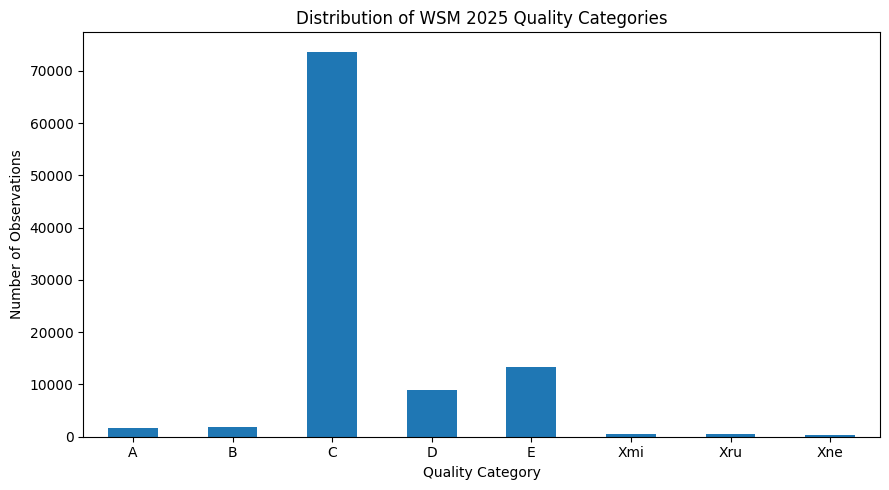

In [8]:
quality_order = ["A", "B", "C", "D", "E", "Xmi", "Xru", "Xne"]
quality_counts_ordered = quality_counts.reindex(quality_order, fill_value=0)

quality_counts_ordered.plot(kind="bar", figsize=(9, 5))
plt.title("Distribution of WSM 2025 Quality Categories")
plt.xlabel("Quality Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Stress-regime analysis

Count the recorded stress-regime categories. Their frequency in this database should **not** be interpreted as their geographic prevalence worldwide, because observation coverage is uneven.

In [9]:
regime_counts = df["REGIME"].value_counts()
regime_counts

REGIME
TF    26270
NF    25069
SS    24162
U     20944
NS     2462
TS     1935
Name: count, dtype: int64

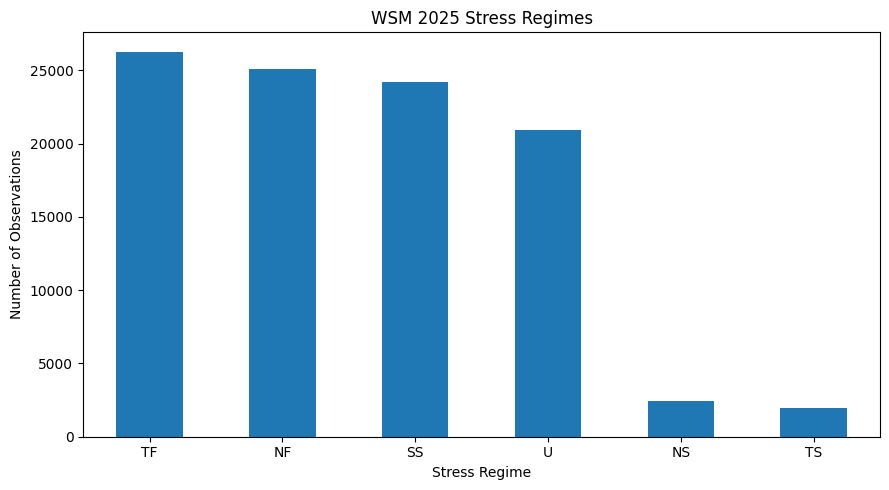

In [10]:
regime_counts.plot(kind="bar", figsize=(9, 5))
plt.title("WSM 2025 Stress Regimes")
plt.xlabel("Stress Regime")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Initial findings and limitations

- The WSM 2025 CSV contains **100,842 observations and 40 columns**.
- **Quality C** is the most frequent category (**73,710 observations**).
- **Thrust faulting (TF)** is the most frequently recorded stress regime (**26,270 observations**), followed by normal faulting and strike-slip faulting.
- **170 observations** have missing geographic coordinates; in the inspected dataset, all 170 have quality code `Xmi`.
- Missing coordinates are a **mapping limitation**, not a reason to delete records from the original dataset. The precise meaning of special quality codes should be checked against official WSM documentation before interpreting or using them in quality-based decisions.
- Observations are not evenly distributed around the world. Consequently, regime frequencies in the WSM database do not directly describe the global geographic prevalence of each tectonic regime.